# Classification Models Built From Scratch (NumPy) – Student Grade Prediction

**Goal:** understand *how* the five classifiers actually work by implementing them ourselves.

| Rule | Detail |
|---|---|
| **scikit-learn is used only for preprocessing** | `train_test_split`, `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `LabelEncoder`, `ColumnTransformer` |
| **Everything else is NumPy** | the 5 models **and** all evaluation metrics (confusion matrix, accuracy, precision, recall, F1, MCC, AUC, ROC) |
| **Dataset** | `student_grade_ses_dataset.csv` – predict `grade_class` (A–F, column AB); columns AA (`final_grade_pct`, leaks the target) and AC (`at_risk_flag`) are dropped |

**Models:** 1) Logistic Regression (softmax) · 2) Decision Tree (CART/Gini) · 3) K-Nearest Neighbors · 4) Gaussian Naive Bayes · 5) Support Vector Machine (linear, squared hinge)

**Contents:** 1 Setup & data → 2 Preprocessing → 3 Metrics from scratch → 4 The five models → 5 Comparison → 6 Confusion matrices → 7 More diagnostics → 8 Conclusion

## 1. Setup & data loading

In [1]:
import time, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

# scikit-learn: PREPROCESSING ONLY
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "student_grade_ses_dataset.csv"   # change if the file is elsewhere

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (12025, 29)


,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,single_parent_household,family_income_bracket,annual_family_income_inr,father_education_level,mother_education_level,father_occupation,mother_occupation,has_internet_access,has_computer_or_laptop,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,1,Middle,403980.0,Primary,Secondary,Clerical / Service,Homemaker,0.0,0,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,0,Middle,572014.0,NaN,Secondary,Business / Self-Employed,Unemployed,0.0,1,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,0,Low,90092.0,No Formal Education,Bachelor's Degree,Clerical / Service,Managerial / Executive,1.0,0,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,0,Lower-Middle,260583.0,Higher Secondary,Secondary,Skilled Labor / Trade,Homemaker,0.0,0,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,1,Upper-Middle,1114986.0,Bachelor's Degree,Higher Secondary,Professional,Clerical / Service,1.0,0,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


In [3]:
# Excel-style column letters -> confirm AA, AB, AC
def excel_col(i):
    s = ""; i += 1
    while i: i, r = divmod(i - 1, 26); s = chr(65 + r) + s
    return s
for i in range(26, 29): print(excel_col(i), "->", raw.columns[i])
print("\nClass distribution:\n", raw["grade_class"].value_counts().to_string())

AA -> final_grade_pct
AB -> grade_class
AC -> at_risk_flag

Class distribution:
 grade_class
C    6161
D    2744
B    2689
F     219
A     212


## 2. Preprocessing
* remove duplicate `student_id` rows; target = column AB; **drop** AA, AC and the identifiers `student_id`, `survey_date`
* numeric → median imputation + standardisation (mean 0, std 1 – essential for gradient descent, KNN and SVM)
* categorical → most-frequent imputation + one-hot encoding
* 80/20 stratified split. The preprocessor is **fitted on the training set only** and then applied to the test set (no leakage).

In [4]:
df = raw.drop_duplicates("student_id").copy()
target_col = df.columns[27]                                   # column AB
drop_cols = [df.columns[26], df.columns[28], "student_id", "survey_date"]   # AA, AC, identifiers
X_df = df.drop(columns=[target_col] + drop_cols)
le = LabelEncoder(); y = le.fit_transform(df[target_col])
class_names = list(le.classes_); K = len(class_names)
print("Target:", target_col, "| classes:", class_names, "| features:", X_df.shape[1])

num_cols = X_df.select_dtypes("number").columns.tolist()
cat_cols = X_df.select_dtypes(exclude="number").columns.tolist()
X_tr_df, X_te_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
X_train = preprocessor.fit_transform(X_tr_df).astype(float)    # plain NumPy arrays from here on
X_test  = preprocessor.transform(X_te_df).astype(float)
feature_names = preprocessor.get_feature_names_out()
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| y_train counts:", np.bincount(y_train))

Target: grade_class | classes: ['A', 'B', 'C', 'D', 'F'] | features: 24
X_train: (9600, 64) | X_test: (2400, 64) | y_train counts: [ 167 2149 4918 2192  174]


## 3. Evaluation metrics from scratch
Everything starts from the **confusion matrix** $C$, where $C_{ij}$ = number of samples of true class $i$ predicted as class $j$.

For each class $k$: $\text{precision}_k=\dfrac{C_{kk}}{\sum_i C_{ik}}$ (column sum), $\text{recall}_k=\dfrac{C_{kk}}{\sum_j C_{kj}}$ (row sum), $F1_k=\dfrac{2PR}{P+R}$.
Multi-class precision / recall / F1 are **support-weighted averages** over classes.

**MCC (multi-class):** with $c$ = correct predictions, $s$ = samples, $p_k$ = times class $k$ was predicted, $t_k$ = times class $k$ truly occurred:
$$\text{MCC}=\frac{c\cdot s-\sum_k p_k t_k}{\sqrt{(s^2-\sum_k p_k^2)(s^2-\sum_k t_k^2)}}$$

**AUC (one-vs-rest, macro):** for each class, AUC = probability that a random positive gets a higher score than a random negative = the Mann–Whitney rank statistic $\dfrac{R_+ - n_+(n_++1)/2}{n_+ n_-}$ (ties get average ranks); then average over the classes. Because AUC only uses the *ranking* of scores, SVM decision values can be used directly.

In [5]:
def confusion_matrix(y_true, y_pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)          # rows = actual, columns = predicted
    return cm

def accuracy(cm):
    return np.trace(cm) / cm.sum()

def precision_recall_f1(cm):
    tp = np.diag(cm).astype(float)
    pred_count, true_count = cm.sum(0), cm.sum(1)
    prec = np.divide(tp, pred_count, out=np.zeros_like(tp), where=pred_count > 0)
    rec  = np.divide(tp, true_count, out=np.zeros_like(tp), where=true_count > 0)
    f1   = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return prec, rec, f1, true_count

def weighted(values, support):
    return (values * support).sum() / support.sum()

def mcc_score(cm):
    c, s = np.trace(cm), cm.sum()
    p, t = cm.sum(0), cm.sum(1)
    den = np.sqrt((s**2 - p @ p) * (s**2 - t @ t))
    return (c * s - p @ t) / den if den > 0 else 0.0

def binary_auc(is_pos, score):
    # average ranks (ties share the mean rank)
    _, inv, counts = np.unique(score, return_inverse=True, return_counts=True)
    ranks = (np.cumsum(counts) - (counts - 1) / 2)[inv]
    n_pos = is_pos.sum(); n_neg = len(is_pos) - n_pos
    return (ranks[is_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def macro_auc_ovr(y_true, scores):
    return np.mean([binary_auc(y_true == k, scores[:, k]) for k in range(scores.shape[1])])

def roc_curve_points(is_pos, score):
    order = np.argsort(-score, kind="stable")
    tps = np.cumsum(is_pos[order]); fps = np.cumsum(~is_pos[order])
    return np.r_[0, fps / fps[-1]], np.r_[0, tps / tps[-1]]

def evaluate(y_true, scores, K):
    y_pred = scores.argmax(1)
    cm = confusion_matrix(y_true, y_pred, K)
    p, r, f, sup = precision_recall_f1(cm)
    return {"Accuracy": accuracy(cm), "AUC": macro_auc_ovr(y_true, scores), "Precision": weighted(p, sup),
            "Recall": weighted(r, sup), "F1": weighted(f, sup), "MCC": mcc_score(cm)}

# tiny sanity check on a hand-made example
_y = np.array([0, 0, 1, 1, 2, 2]); _p = np.array([0, 1, 1, 1, 2, 0])
print(confusion_matrix(_y, _p, 3)); print("accuracy =", accuracy(confusion_matrix(_y, _p, 3)), "(expected 4/6 = 0.667)")

[[1 1 0]
 [0 2 0]
 [1 0 1]]
accuracy = 0.6666666666666666 (expected 4/6 = 0.667)


## 4. The five models
All models share the same tiny interface: `fit(X, y, K)`, `predict_proba(X)` / `decision_function(X)` and `predict(X)`.
We store each model's **score matrix** on the test set (probabilities, or margins for the SVM); the predicted class is its `argmax`.

In [6]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)          # subtract the max for numerical stability
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

scores, fit_time, models = {}, {}, {}

### 4.1 Logistic Regression (multinomial / softmax)
Model: class scores $z = XW + b$, probabilities $P=\text{softmax}(z)$.
Loss: **cross-entropy** with L2 penalty, $L=-\frac1n\sum_i \log P_{i,y_i}+\frac{\lambda}{2}\lVert W\rVert^2$.
Its gradient is beautifully simple: $\nabla_W L = \frac1n X^\top (P-Y) + \lambda W$, with $Y$ the one-hot labels.
We minimise it with **batch gradient descent**: $W \leftarrow W-\eta\nabla_W L$.

In [7]:
class LogisticRegressionScratch:
    def __init__(self, lr=0.5, n_iter=1500, l2=1e-3):
        self.lr, self.n_iter, self.l2 = lr, n_iter, l2

    def fit(self, X, y, K):
        n, d = X.shape
        Y = np.eye(K)[y]                              # one-hot labels
        self.W, self.b = np.zeros((d, K)), np.zeros(K)
        self.loss_history = []
        for it in range(self.n_iter):
            P = softmax(X @ self.W + self.b)          # forward pass
            G = (P - Y) / n                           # dL/dz
            self.W -= self.lr * (X.T @ G + self.l2 * self.W)
            self.b -= self.lr * G.sum(axis=0)
            if it % 10 == 0:
                self.loss_history.append(-np.log(P[np.arange(n), y] + 1e-12).mean() + 0.5 * self.l2 * (self.W ** 2).sum())
        return self

    def predict_proba(self, X): return softmax(X @ self.W + self.b)
    def predict(self, X): return self.predict_proba(X).argmax(1)

t = time.time()
models["Logistic Regression"] = LogisticRegressionScratch().fit(X_train, y_train, K)
fit_time["Logistic Regression"] = time.time() - t
scores["Logistic Regression"] = models["Logistic Regression"].predict_proba(X_test)
print(f"trained in {fit_time['Logistic Regression']:.1f}s | loss {models['Logistic Regression'].loss_history[0]:.3f} -> {models['Logistic Regression'].loss_history[-1]:.3f}")

trained in 3.9s | loss 1.610 -> 0.940


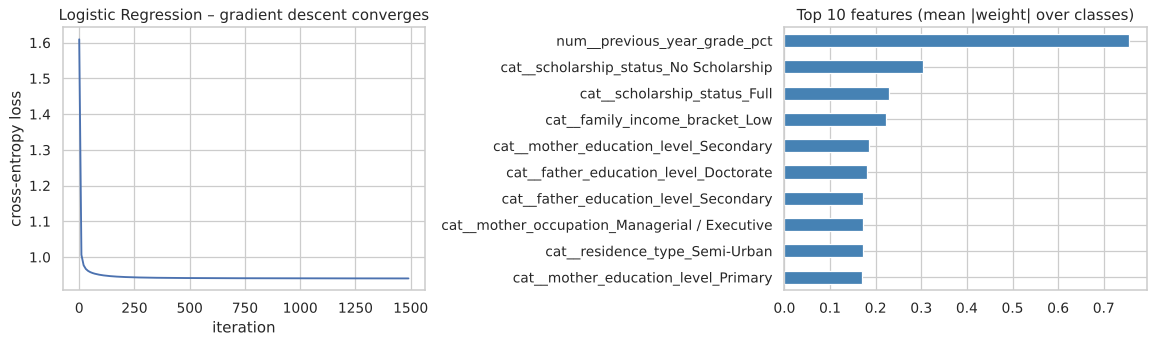

In [8]:
lr_model = models["Logistic Regression"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(np.arange(len(lr_model.loss_history)) * 10, lr_model.loss_history); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Logistic Regression – gradient descent converges")
coef = pd.Series(np.abs(lr_model.W).mean(1), index=feature_names).sort_values().tail(10)
coef.plot.barh(ax=ax[1], color="steelblue"); ax[1].set_title("Top 10 features (mean |weight| over classes)")
plt.tight_layout(); plt.show()

### 4.2 Decision Tree (CART, Gini impurity)
A tree repeatedly asks a yes/no question `feature ≤ threshold` to split the data into purer groups.
**Gini impurity** of a node: $G=1-\sum_k p_k^2$ (0 = pure). For every feature and every candidate threshold we compute the weighted impurity of the two children $\frac{n_L}{n}G_L+\frac{n_R}{n}G_R$ and take the best split.
To search all thresholds of one feature at once: sort by the feature, take **cumulative class counts**, and the left/right counts at every cut point come for free.
Growth stops at `max_depth` or when a split would leave fewer than `min_samples_leaf` samples. A leaf predicts its class proportions.

In [9]:
class _Node:
    __slots__ = ("feature", "threshold", "left", "right", "proba")

class DecisionTreeScratch:
    def __init__(self, max_depth=6, min_samples_leaf=10):
        self.max_depth, self.min_samples_leaf = max_depth, min_samples_leaf

    @staticmethod
    def _gini(counts):                                    # counts: (..., K) class counts
        n = counts.sum(-1, keepdims=True)
        p = counts / np.maximum(n, 1)
        return 1 - (p ** 2).sum(-1)

    def fit(self, X, y, K):
        self.K = K
        self.importances = np.zeros(X.shape[1])
        self.root = self._grow(X, np.eye(K)[y], depth=0)
        self.importances /= self.importances.sum()
        return self

    def _best_split(self, X, Y):
        n, msl = len(Y), self.min_samples_leaf
        total = Y.sum(0)
        best_feature, best_thr, best_imp = None, None, self._gini(total)   # a split must beat the parent
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="stable"); xs = X[order, j]
            left = np.cumsum(Y[order], axis=0)[:-1]       # class counts on the left for every cut position
            right = total - left
            nl = np.arange(1, n)
            valid = (xs[:-1] < xs[1:]) & (nl >= msl) & (n - nl >= msl)   # real cut + leaf-size constraint
            if not valid.any(): continue
            imp = (nl * self._gini(left) + (n - nl) * self._gini(right)) / n
            imp[~valid] = np.inf
            i = imp.argmin()
            if imp[i] < best_imp - 1e-12:
                best_feature, best_thr, best_imp = j, (xs[i] + xs[i + 1]) / 2, imp[i]
        return best_feature, best_thr, best_imp

    def _grow(self, X, Y, depth):
        node = _Node(); node.feature = None
        counts = Y.sum(0); node.proba = counts / counts.sum()
        if depth >= self.max_depth or len(Y) < 2 * self.min_samples_leaf or (counts > 0).sum() == 1:
            return node                                    # leaf
        j, thr, imp = self._best_split(X, Y)
        if j is None: return node
        mask = X[:, j] <= thr
        self.importances[j] += len(Y) * (self._gini(counts) - imp)   # impurity decrease -> feature importance
        node.feature, node.threshold = j, thr
        node.left = self._grow(X[mask], Y[mask], depth + 1)
        node.right = self._grow(X[~mask], Y[~mask], depth + 1)
        return node

    def _descend(self, node, X, idx, out):
        if node.feature is None: out[idx] = node.proba; return
        go_left = X[idx, node.feature] <= node.threshold
        self._descend(node.left, X, idx[go_left], out)
        self._descend(node.right, X, idx[~go_left], out)

    def predict_proba(self, X):
        out = np.zeros((len(X), self.K)); self._descend(self.root, X, np.arange(len(X)), out); return out
    def predict(self, X): return self.predict_proba(X).argmax(1)

    def show(self, names, class_names, node=None, depth=0, max_show=2):
        node = node or self.root; pad = "    " * depth
        if node.feature is None or depth >= max_show:
            print(f"{pad}-> predict {class_names[node.proba.argmax()]}  (class mix: " + ", ".join(f"{c}:{p:.2f}" for c, p in zip(class_names, node.proba)) + ")"); return
        print(f"{pad}if {names[node.feature]} <= {node.threshold:.3f}:"); self.show(names, class_names, node.left, depth + 1, max_show)
        print(f"{pad}else:"); self.show(names, class_names, node.right, depth + 1, max_show)

t = time.time()
models["Decision Tree"] = DecisionTreeScratch(max_depth=6, min_samples_leaf=10).fit(X_train, y_train, K)
fit_time["Decision Tree"] = time.time() - t
scores["Decision Tree"] = models["Decision Tree"].predict_proba(X_test)
print(f"trained in {fit_time['Decision Tree']:.1f}s\n\nFirst two levels of the learned tree:")
models["Decision Tree"].show(feature_names, class_names)

trained in 0.8s

First two levels of the learned tree:
if num__previous_year_grade_pct <= 0.392:
    if num__previous_year_grade_pct <= -1.085:
        -> predict D  (class mix: A:0.00, B:0.03, C:0.38, D:0.56, F:0.03)
    else:
        -> predict C  (class mix: A:0.00, B:0.15, C:0.58, D:0.25, F:0.02)
else:
    if num__previous_year_grade_pct <= 1.136:
        -> predict C  (class mix: A:0.02, B:0.35, C:0.54, D:0.08, F:0.02)
    else:
        -> predict B  (class mix: A:0.09, B:0.54, C:0.34, D:0.02, F:0.01)


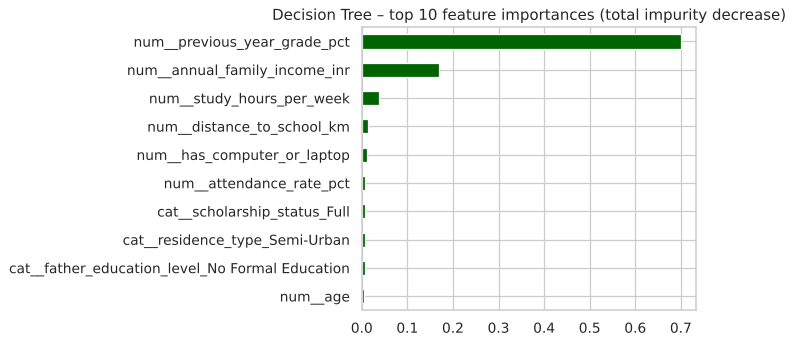

In [10]:
imp = pd.Series(models["Decision Tree"].importances, index=feature_names).sort_values().tail(10)
imp.plot.barh(figsize=(8, 4), color="darkgreen"); plt.title("Decision Tree – top 10 feature importances (total impurity decrease)")
plt.tight_layout(); plt.show()

### 4.3 K-Nearest Neighbors
No training – just memorise the data. To classify a point: compute its (Euclidean) distance to **every** training point, take the $k$ closest, and let them vote; the class share among the neighbours is the score.
Fast distance trick: $\lVert a-b\rVert^2=\lVert a\rVert^2+\lVert b\rVert^2-2\,a\!\cdot\! b$, which turns all distances into one matrix product. Features must be scaled (done in preprocessing), otherwise large-valued features dominate.

In [11]:
class KNNScratch:
    def __init__(self, k=15): self.k = k

    def fit(self, X, y, K):
        self.X, self.y, self.K = X, y, K
        self.sq = (X ** 2).sum(axis=1)                    # ||b||^2 for every training point
        return self

    def predict_proba(self, X, chunk=500):
        out = np.zeros((len(X), self.K)); eye = np.eye(self.K)
        for s in range(0, len(X), chunk):                 # chunks keep the distance matrix small
            A = X[s:s + chunk]
            d2 = (A ** 2).sum(axis=1)[:, None] + self.sq[None, :] - 2 * A @ self.X.T
            nearest = np.argpartition(d2, self.k, axis=1)[:, :self.k]     # indices of the k smallest distances
            out[s:s + chunk] = eye[self.y[nearest]].mean(axis=1)          # vote share per class
        return out
    def predict(self, X): return self.predict_proba(X).argmax(1)

t = time.time()
models["KNN"] = KNNScratch(k=15).fit(X_train, y_train, K)
scores["KNN"] = models["KNN"].predict_proba(X_test)
fit_time["KNN"] = time.time() - t
print(f"fit + predict in {fit_time['KNN']:.1f}s (all the work happens at prediction time)")

fit + predict in 0.3s (all the work happens at prediction time)


### 4.4 Gaussian Naive Bayes
Bayes' rule with a **"naive" independence assumption**: $P(c\mid x)\propto P(c)\prod_j P(x_j\mid c)$, where each feature given the class is Gaussian,
$P(x_j\mid c)=\mathcal N(x_j;\mu_{cj},\sigma^2_{cj})$.
"Training" = computing the class priors and the per-class mean and variance of every feature. Prediction works with **log**-probabilities (sums instead of products, no underflow), then a softmax gives posteriors.

In [12]:
class GaussianNBScratch:
    def __init__(self, var_smoothing=1e-9): self.vs = var_smoothing

    def fit(self, X, y, K):
        eps = self.vs * X.var(axis=0).max()               # tiny constant to avoid division by zero variance
        self.mean = np.array([X[y == c].mean(axis=0) for c in range(K)])          # (K, d)
        self.var = np.array([X[y == c].var(axis=0) for c in range(K)]) + eps      # (K, d)
        self.log_prior = np.log(np.bincount(y, minlength=K) / len(y))
        return self

    def predict_proba(self, X):
        # log N(x | mu, var) summed over features, for every class
        log_lik = -0.5 * (np.log(2 * np.pi * self.var)[None] + (X[:, None, :] - self.mean[None]) ** 2 / self.var[None]).sum(axis=2)
        return softmax(log_lik + self.log_prior)          # posterior = normalised (log-likelihood + log-prior)
    def predict(self, X): return self.predict_proba(X).argmax(1)

t = time.time()
models["Naive Bayes (Gaussian)"] = GaussianNBScratch().fit(X_train, y_train, K)
fit_time["Naive Bayes (Gaussian)"] = time.time() - t
scores["Naive Bayes (Gaussian)"] = models["Naive Bayes (Gaussian)"].predict_proba(X_test)
print(f"trained in {fit_time['Naive Bayes (Gaussian)']:.3f}s")

trained in 0.008s


### 4.5 Support Vector Machine (linear, one-vs-rest)
An SVM finds the hyperplane $f(x)=w\cdot x+b$ with the **largest margin**. With labels $t_i\in\{-1,+1\}$, a point is fine if $t_i f(x_i)\ge 1$; otherwise it pays a **slack** $\xi_i=\max(0,\,1-t_i f(x_i))$.
We minimise the regularised **squared-hinge** loss (the "L2-SVM"): $L=\frac1n\sum_i \xi_i^2+\frac{\lambda}{2}\lVert w\rVert^2$, whose gradient is $-\frac{2}{n}\sum_i t_i\xi_i x_i+\lambda w$ – again solved with gradient descent.
For 5 classes we train **5 one-vs-rest SVMs** at once (one weight column per class); the predicted class has the **largest margin** $f_k(x)$. SVMs output margins, not probabilities – but AUC only needs rankings, so margins work directly.
*(A non-linear RBF kernel would need a kernel matrix / SMO solver; the linear SVM shows the core idea of margin + hinge loss.)*

In [13]:
class LinearSVMScratch:
    def __init__(self, lam=1e-4, lr=0.1, n_iter=1500):
        self.lam, self.lr, self.n_iter = lam, lr, n_iter

    def fit(self, X, y, K):
        n, d = X.shape
        T = -np.ones((n, K)); T[np.arange(n), y] = 1      # +1 for the true class, -1 for the others
        self.W, self.b = np.zeros((d, K)), np.zeros(K)
        self.loss_history = []
        for it in range(self.n_iter):
            slack = np.maximum(0, 1 - T * (X @ self.W + self.b))     # hinge slack of every sample / class
            gz = -2 * T * slack / n                                   # dL/d(score)
            self.W -= self.lr * (X.T @ gz + self.lam * self.W)
            self.b -= self.lr * gz.sum(axis=0)
            if it % 10 == 0:
                self.loss_history.append((slack ** 2).mean() + 0.5 * self.lam * (self.W ** 2).sum())
        return self

    def decision_function(self, X): return X @ self.W + self.b     # signed margin per class
    def predict(self, X): return self.decision_function(X).argmax(1)

t = time.time()
models["Support Vector Machine (SVM)"] = LinearSVMScratch().fit(X_train, y_train, K)
fit_time["Support Vector Machine (SVM)"] = time.time() - t
scores["Support Vector Machine (SVM)"] = models["Support Vector Machine (SVM)"].decision_function(X_test)
h = models["Support Vector Machine (SVM)"].loss_history
print(f"trained in {fit_time['Support Vector Machine (SVM)']:.1f}s | loss {h[0]:.3f} -> {h[-1]:.3f}")

trained in 2.7s | loss 1.000 -> 0.443


## 5. Comparison of all models
Metrics computed with **our own** functions from section 3 on the 2,400-row hold-out test set. AUC = one-vs-rest macro; Precision / Recall / F1 = support-weighted.

In [14]:
results = pd.DataFrame({n: evaluate(y_test, s, K) for n, s in scores.items()}).T
results.index.name = "ML Model"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model,,,,,,
Logistic Regression,0.5796,0.7220,0.5565,0.5796,0.5477,0.2796
Decision Tree,0.5692,0.7278,0.5503,0.5692,0.5386,0.2619
KNN,0.5433,0.6583,0.5314,0.5433,0.5008,0.2016
Naive Bayes (Gaussian),0.3667,0.6604,0.4604,0.3667,0.3477,0.1676
Support Vector Machine (SVM),0.5704,0.7165,0.5535,0.5704,0.5228,0.2513


In [15]:
results.round(4).style.highlight_max(axis=0, color="lightgreen").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model,,,,,,
Logistic Regression,0.5796,0.7220,0.5565,0.5796,0.5477,0.2796
Decision Tree,0.5692,0.7278,0.5503,0.5692,0.5386,0.2619
KNN,0.5433,0.6583,0.5314,0.5433,0.5008,0.2016
Naive Bayes (Gaussian),0.3667,0.6604,0.4604,0.3667,0.3477,0.1676
Support Vector Machine (SVM),0.5704,0.7165,0.5535,0.5704,0.5228,0.2513


In [16]:
print("Best model per metric:\n"); print(results.idxmax().to_string())
print("\nOverall winner (mean rank across the 6 metrics):", results.rank(ascending=False).mean(axis=1).idxmin())

Best model per metric:

Accuracy     Logistic Regression
AUC                Decision Tree
Precision    Logistic Regression
Recall       Logistic Regression
F1           Logistic Regression
MCC          Logistic Regression

Overall winner (mean rank across the 6 metrics): Logistic Regression


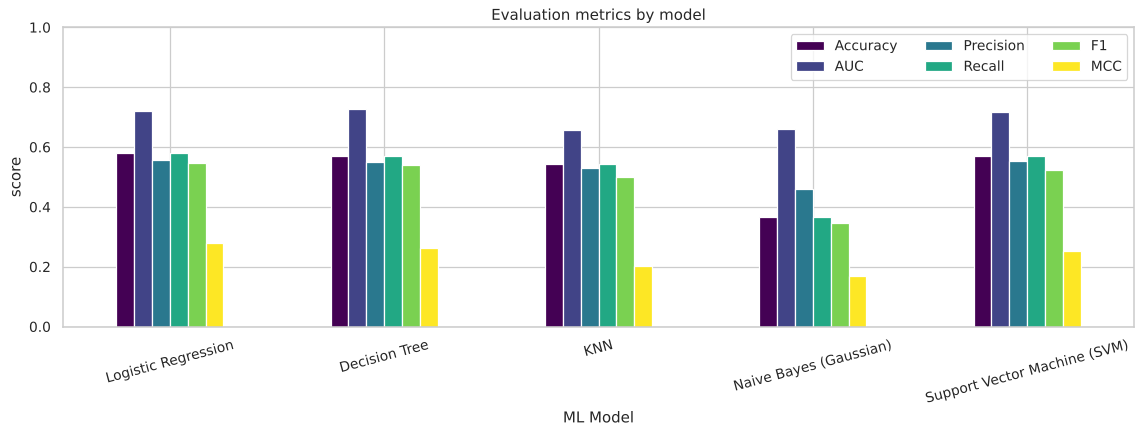

In [17]:
results.plot.bar(figsize=(13, 5), rot=15, colormap="viridis")
plt.title("Evaluation metrics by model"); plt.ylim(0, 1); plt.ylabel("score"); plt.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

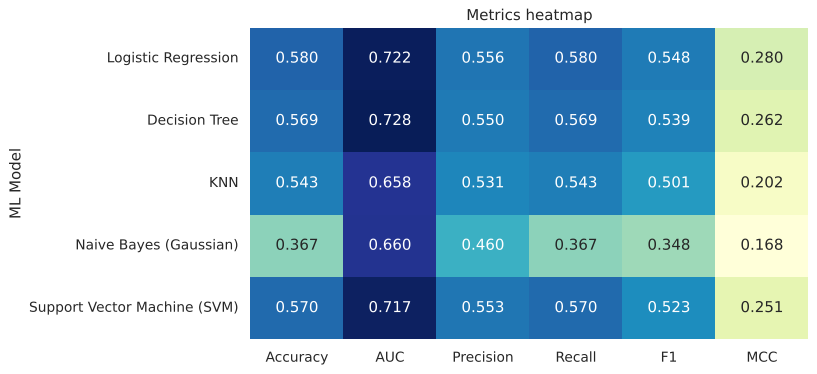

In [18]:
plt.figure(figsize=(8, 4.5)); sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False)
plt.title("Metrics heatmap"); plt.show()

## 6. Confusion matrices – all models
Rows = actual class, columns = predicted class. Left: raw counts. Right: **row-normalised** (each row sums to 1, so the diagonal is the per-class **recall**) – this makes the minority classes A and F visible.

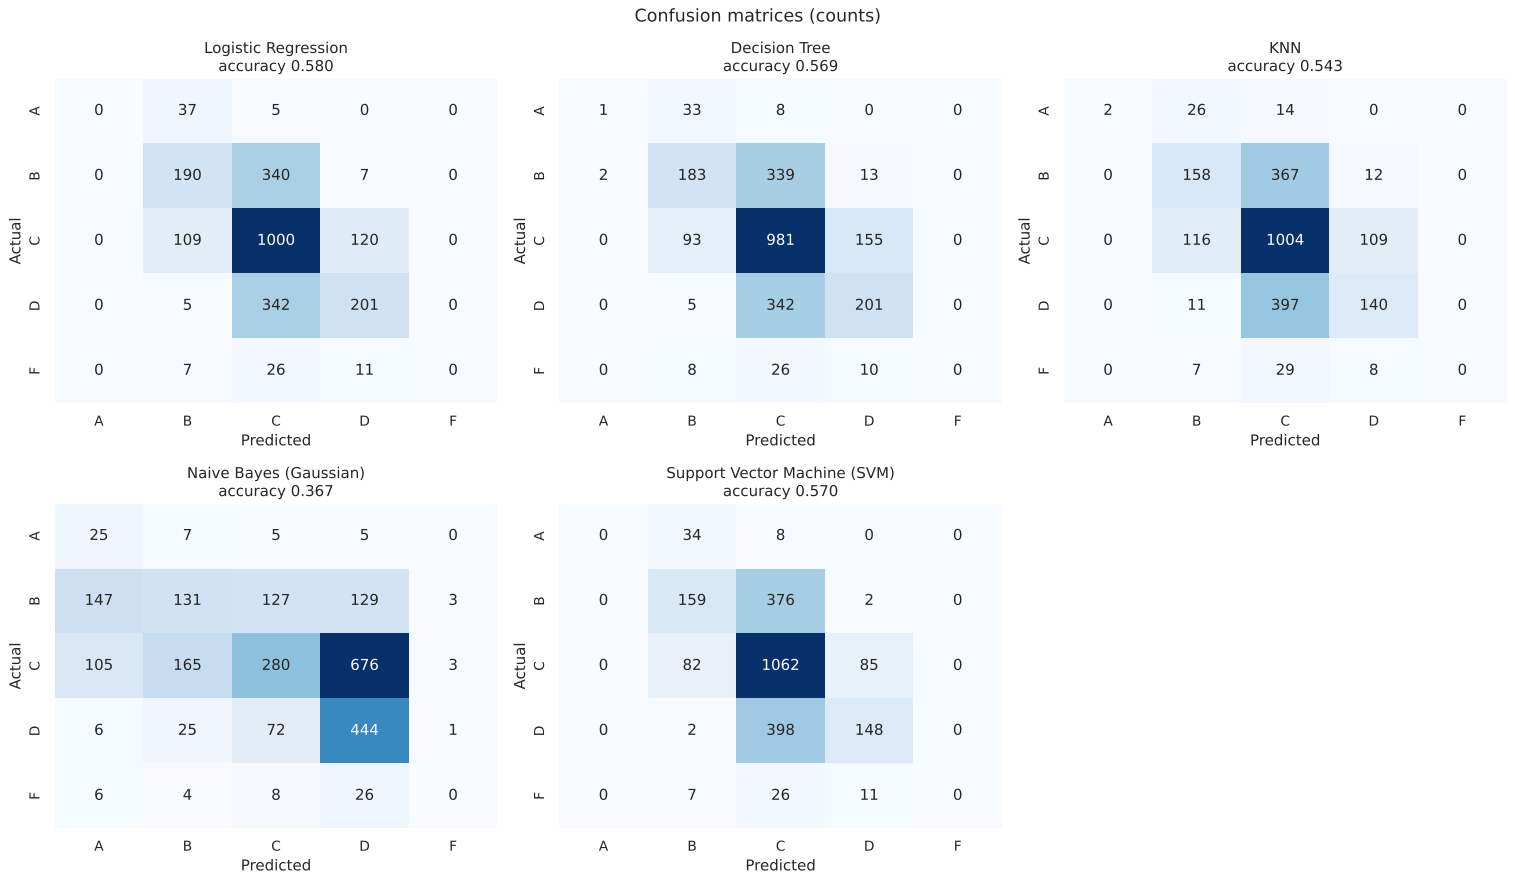

In [19]:
cms = {n: confusion_matrix(y_test, s.argmax(1), K) for n, s in scores.items()}
fig, axes = plt.subplots(2, 3, figsize=(17, 10)); axes = axes.ravel()
for a, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=a)
    a.set_title(f"{n}\naccuracy {accuracy(cm):.3f}"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
axes[-1].axis("off"); plt.suptitle("Confusion matrices (counts)", fontsize=14); plt.tight_layout(); plt.show()

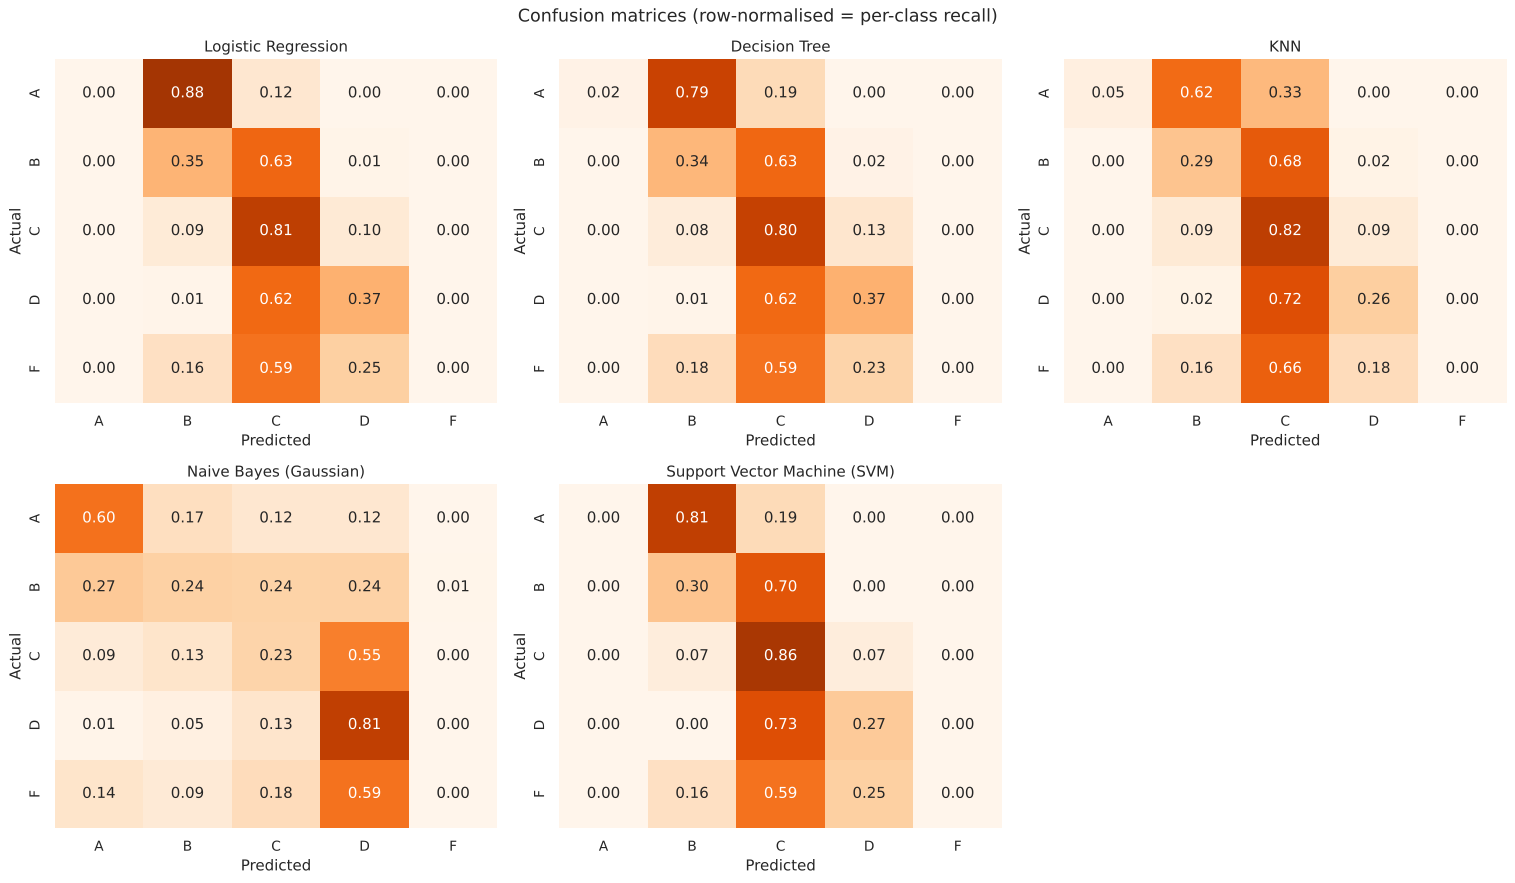

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10)); axes = axes.ravel()
for a, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=a)
    a.set_title(n); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
axes[-1].axis("off"); plt.suptitle("Confusion matrices (row-normalised = per-class recall)", fontsize=14); plt.tight_layout(); plt.show()

## 7. More diagnostics

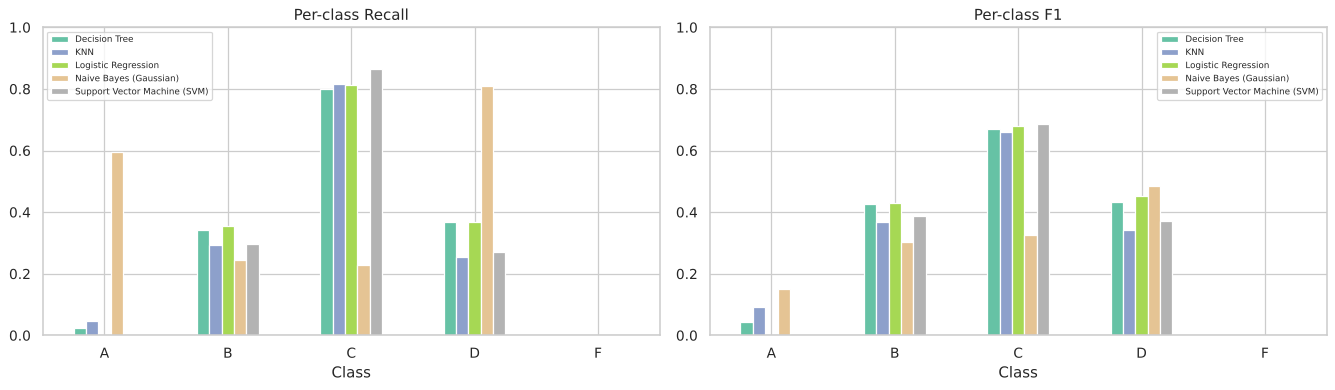

Model,Decision Tree,KNN,Logistic Regression,Naive Bayes (Gaussian),Support Vector Machine (SVM)
Class,,,,,
A,0.024,0.048,0.000,0.595,0.000
B,0.341,0.294,0.354,0.244,0.296
C,0.798,0.817,0.814,0.228,0.864
D,0.367,0.255,0.367,0.810,0.270
F,0.000,0.000,0.000,0.000,0.000


In [21]:
# Per-class precision / recall / F1 for every model
rows = []
for n, cm in cms.items():
    p, r, f, sup = precision_recall_f1(cm)
    for k, c in enumerate(class_names):
        rows.append({"Model": n, "Class": c, "Precision": p[k], "Recall": r[k], "F1": f[k], "Support": sup[k]})
per_class = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, m in zip(ax, ["Recall", "F1"]):
    per_class.pivot(index="Class", columns="Model", values=m).loc[class_names].plot.bar(ax=a, rot=0, colormap="Set2")
    a.set_title(f"Per-class {m}"); a.set_ylim(0, 1); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
per_class.pivot(index="Class", columns="Model", values="Recall").round(3)

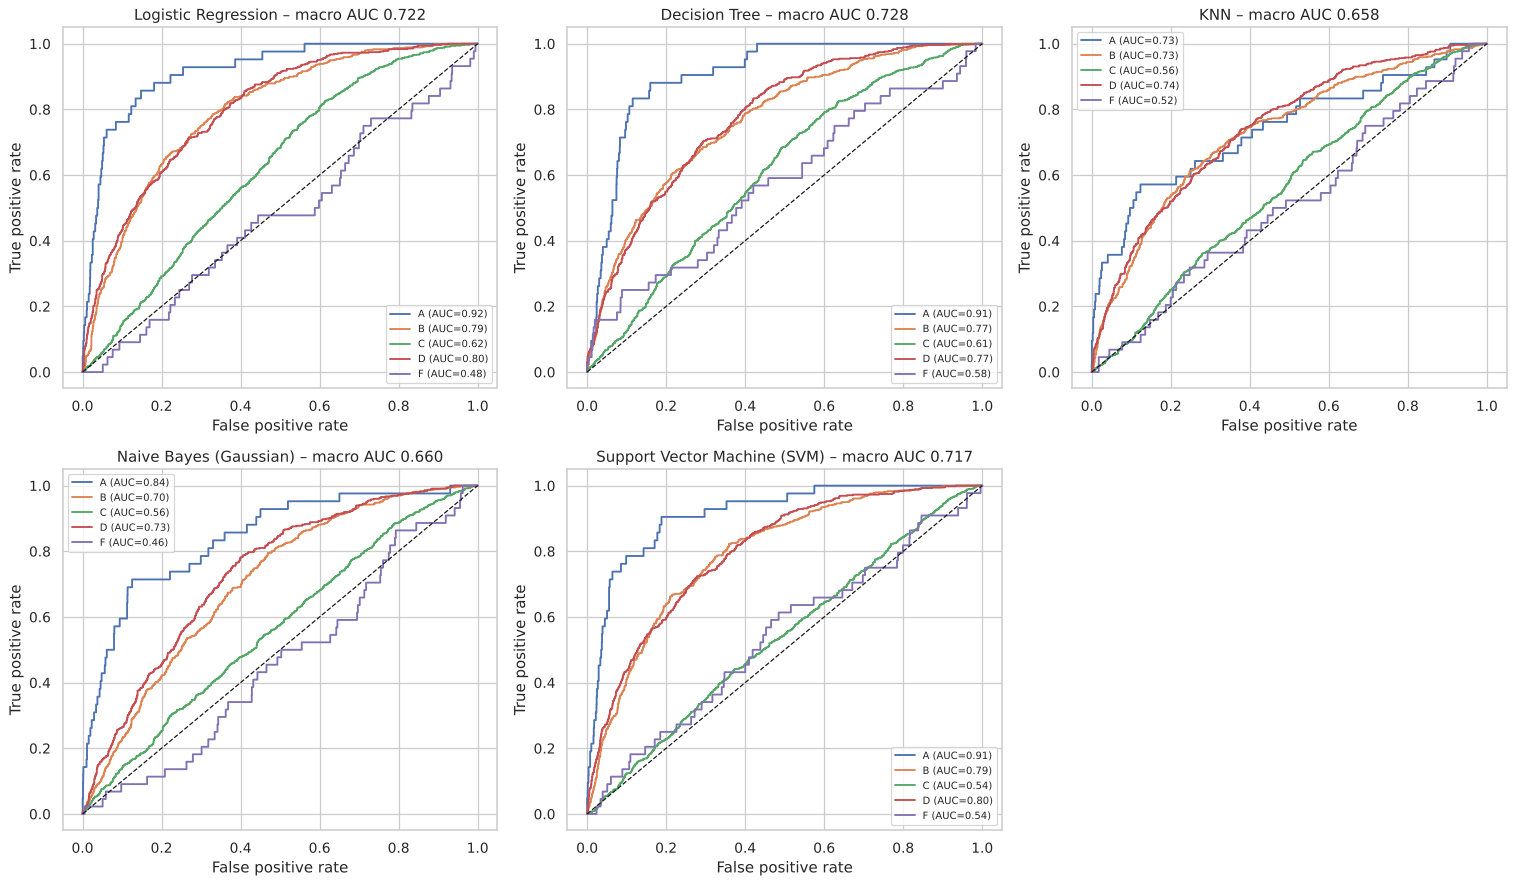

In [22]:
# ROC curves one-vs-rest (computed with our own roc_curve_points)
fig, axes = plt.subplots(2, 3, figsize=(17, 10)); axes = axes.ravel()
for a, (n, s) in zip(axes, scores.items()):
    for k, c in enumerate(class_names):
        fpr, tpr = roc_curve_points(y_test == k, s[:, k])
        a.plot(fpr, tpr, label=f"{c} (AUC={binary_auc(y_test == k, s[:, k]):.2f})")
    a.plot([0, 1], [0, 1], "k--", lw=1); a.set_title(f"{n} – macro AUC {results.loc[n, 'AUC']:.3f}")
    a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate"); a.legend(fontsize=8)
axes[-1].axis("off"); plt.tight_layout(); plt.show()

In [23]:
# Overfitting check (train vs test accuracy) and training time
def predict_of(name, X):
    m = models[name]
    return (m.decision_function(X) if hasattr(m, "decision_function") else m.predict_proba(X)).argmax(1)
diag = pd.DataFrame({
    "Train accuracy": {n: (predict_of(n, X_train) == y_train).mean() for n in models},
    "Test accuracy":  {n: (predict_of(n, X_test) == y_test).mean() for n in models},
    "Fit time (s)":   fit_time}).round(3)
diag["Gap"] = (diag["Train accuracy"] - diag["Test accuracy"]).round(3)
diag

,Train accuracy,Test accuracy,Fit time (s),Gap
Logistic Regression,0.591,0.580,3.875,0.011
Decision Tree,0.593,0.569,0.760,0.024
KNN,0.597,0.543,0.276,0.054
Naive Bayes (Gaussian),0.377,0.367,0.008,0.010
Support Vector Machine (SVM),0.577,0.570,2.689,0.007


## 8. Conclusion
**Winner on this dataset: Logistic Regression** – best accuracy, F1 and MCC, essentially no overfitting, and the cheapest to understand. The Decision Tree has the highest AUC; the linear SVM is a close third.

| Model | What we learned from building it |
|---|---|
| **Logistic Regression** | Gradient descent on the cross-entropy loss converges smoothly. The signal is mostly linear (`previous_year_grade_pct` dominates), so this simple model is hard to beat. |
| **Decision Tree** | Depth-limited CART splits mostly on `previous_year_grade_pct` and family income. Highest AUC, slightly lower accuracy than LR; train ≈ test, so depth 6 is not overfitting. |
| **KNN** | No training, all cost at prediction time. With ~60 mostly one-hot features, distances become less informative, and the 15 neighbours mostly vote for the majority class C. |
| **Naive Bayes** | Worst accuracy: Gaussian + independence assumptions fit one-hot, correlated features poorly, so it over-predicts class D. It is the only model that finds many of the rare class A (see the row-normalised confusion matrix), at the cost of many false alarms. |
| **SVM (linear)** | Margin-based, performs close to LR. One-vs-rest margins are not probabilities, but their ranking is enough for AUC. |

**Important caveat – class imbalance:** classes A and F are ~2% each. All models except Naive Bayes almost never predict them (recall ≈ 0 in the confusion matrices), so accuracy (~55–58%) hides weak minority-class performance and MCC stays below 0.3. Class weights, resampling or threshold tuning are the natural next steps.

*Validation note:* the from-scratch implementations were cross-checked offline against scikit-learn – Decision Tree, KNN and Naive Bayes give identical predictions, the linear SVM matches `LinearSVC`, and Logistic Regression agrees within 0.2 accuracy points.